# Week 4: Student Spending & Budget Analyzer

**Name:** Nida
**Program:** IEEE LGU Student Branch AI/ML Cohort One

## 1. Project Introduction

**Objective:** The goal of this notebook is to use Pandas, NumPy and Matplotlib to analyze a small dataset, and to understand how Python libraries can turn raw data into useful information.

**Dataset description:** The dataset is *fictional* and contains 12 student expense records. The amounts are in arbitrary currency units and do not represent real student spending. In this notebook, we analyze spending by **category** and by **payment method**.

## 2. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

- **Pandas** is used to create, organize, explore and group tabular data (DataFrames).
- **NumPy** is used for numerical calculations and statistics, such as the mean.
- **Matplotlib** is used to create charts and visualizations.

## 3. Create the Dataset

In [2]:
data = {
    "Category": [
        "Food", "Transport", "Education", "Food",
        "Entertainment", "Transport", "Food",
        "Education", "Entertainment", "Transport",
        "Food", "Education"
    ],
    "Amount": [
        500, 150, 800, 350,
        400, 200, 600,
        700, 250, 180,
        450, 900
    ],
    "Payment_Method": [
        "Cash", "Card", "Online", "Cash",
        "Card", "Cash", "Online",
        "Online", "Card", "Cash",
        "Cash", "Online"
    ]
}

df = pd.DataFrame(data)
display(df)

,Category,Amount,Payment_Method
0,Food,500,Cash
1,Transport,150,Card
2,Education,800,Online
3,Food,350,Cash
4,Entertainment,400,Card
5,Transport,200,Cash
6,Food,600,Online
7,Education,700,Online
8,Entertainment,250,Card
9,Transport,180,Cash


The dataset contains three columns:
- **Category:** the type of expense (Food, Transport, Education or Entertainment).
- **Amount:** the expense amount in arbitrary units.
- **Payment_Method:** how the expense was paid (Cash, Card or Online).

## 4. Explore the Data

In [3]:
df.head()

,Category,Amount,Payment_Method
0,Food,500,Cash
1,Transport,150,Card
2,Education,800,Online
3,Food,350,Cash
4,Entertainment,400,Card


In [4]:
df.shape

(12, 3)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Category        12 non-null     str  
 1   Amount          12 non-null     int64
 2   Payment_Method  12 non-null     str  
dtypes: int64(1), str(2)
memory usage: 420.0 bytes


In [6]:
df.describe(include="all")

,Category,Amount,Payment_Method
count,12,12.000000,12
unique,4,NaN,3
top,Food,NaN,Cash
freq,4,NaN,5
mean,NaN,456.666667,NaN
std,NaN,250.429933,NaN
min,NaN,150.000000,NaN
25%,NaN,237.500000,NaN
50%,NaN,425.000000,NaN
75%,NaN,625.000000,NaN


**What we learned from the outputs:**
- `df.shape` shows that the dataset has **12 rows and 3 columns**, so there are 12 expense records.
- `df.info()` shows that `Category` and `Payment_Method` are text columns, while `Amount` is a numeric (integer) column. All columns have 12 non-null values.
- `df.describe(include="all")` summarizes the numeric column (count, mean, min, max and quartiles) and, for the text columns, the number of unique values and the most frequent value. The most frequent category is **Food** (4 records).

## 5. Check Data Quality

In [7]:
df.isnull().sum()

Category          0
Amount            0
Payment_Method    0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

No missing values were found, because every column has a count of **0** missing entries. No duplicate rows were found either (the duplicate count is **0**). This means the dataset is clean and needs no further cleaning.

## 6. Calculate Statistics

**Question 1:** What is the total spending across all entries?

In [9]:
total_spending = df["Amount"].sum()
print("Total spending:", total_spending)

Total spending: 5480


**Question 2:** What is the average spending per entry?

In [10]:
average_spending = np.mean(df["Amount"])
print("Average spending:", average_spending)

Average spending: 456.6666666666667


**Question 3:** Which category has the highest total spending?

In [11]:
category_spending = df.groupby("Category")["Amount"].sum()
print(category_spending)

highest_category = category_spending.idxmax()
print("Category with the highest spending:", highest_category)

Category
Education        2400
Entertainment     650
Food             1900
Transport         530
Name: Amount, dtype: int64
Category with the highest spending: Education


**Question 4:** What is the highest individual expense?

In [12]:
highest_expense = df["Amount"].max()
print("Highest individual expense:", highest_expense)

Highest individual expense: 900


**Question 5:** How much was spent through each payment method?

In [13]:
payment_spending = df.groupby("Payment_Method")["Amount"].sum()
print(payment_spending)

Payment_Method
Card       800
Cash      1680
Online    3000
Name: Amount, dtype: int64


**Findings in my own words:**
- Total spending is **5480** units, and the average spending per entry is about **456.67** units.
- **Education** has the highest total spending (2400 units), followed by Food (1900), Entertainment (650) and Transport (530).
- The highest individual expense is **900** units, and it belongs to the Education category.
- By payment method, **Online** payments account for the most money (3000 units), followed by Cash (1680) and Card (800).

## 7. Visualize Spending

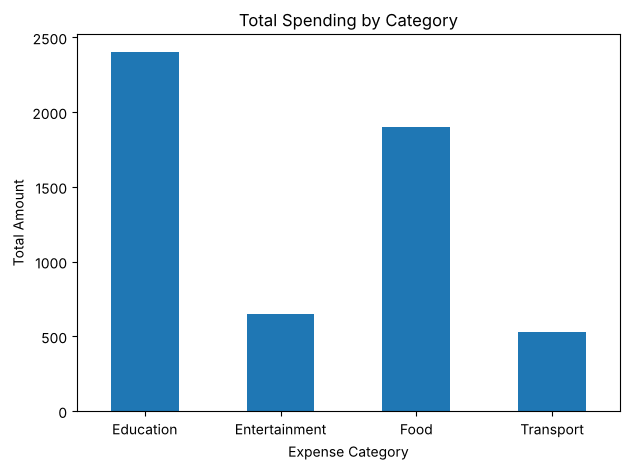

In [14]:
category_spending = df.groupby("Category")["Amount"].sum()

category_spending.plot(kind="bar")
plt.title("Total Spending by Category")
plt.xlabel("Expense Category")
plt.ylabel("Total Amount")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

The bar chart shows total spending for each category. **Education** has the tallest bar, so it has the highest spending in this dataset. The chart makes it easy to compare the categories at a glance, which is harder to do by reading the numbers alone.

## 8. Findings and Conclusion

1. **Total spending:** The total spending in the dataset is **5480** units.
2. **Highest category:** **Education** has the highest total spending (**2400** units), with Food second at 1900 units.
3. **Payment methods:** In this dataset, **Online** payments account for the largest amount (3000 units), while Card payments account for the smallest (800 units). Most of the spending was therefore paid online.
4. **Pandas and NumPy:** Pandas made it easy to store the data in a table, check its quality (missing values and duplicates) and group it with `groupby` to total spending by category or payment method. NumPy helped calculate the average with `np.mean`. Just a few lines of code produced a lot of useful information.
5. **Bar chart:** The chart showed the differences between categories at a glance. Education clearly stands out as the biggest spending category, which is less obvious when reading only the numbers.
6. **Managing spending:** A student could record their expenses by category every week (for example in a spreadsheet) and set a budget limit for each category.

*Note: The dataset is small and fictional, so these conclusions describe this dataset only and not all students.*